# Portfolio Assignment: Deep Learning Blog Post
**Name:** Kent Ormillada

**DS413**

"When should training stop—and what does 'one more epoch' actually cost once validation loss stops improving?"

In [1]:
!pip install -q pytorch-lightning

In [2]:
import pytorch_lightning as pl
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms


class FashionMNISTDataModule(pl.LightningDataModule):

  def __init__(self, data_dir="./data", batch_size=64, val_split=5000):
    super().__init__()
    self.data_dir = data_dir
    self.batch_size = batch_size
    self.val_split = val_split
    self.transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.2860,), (0.3530,)),
    ])

  def prepare_data(self):
    datasets.FashionMNIST(self.data_dir, train=True, download=True)
    datasets.FashionMNIST(self.data_dir, train=False, download=True)

  def setup(self, stage=None):
    if stage in ("fit", None):
      full_train = datasets.FashionMNIST(
          self.data_dir, train=True, transform=self.transform
      )
      train_len = len(full_train) - self.val_split
      self.train_ds, self.val_ds = random_split(
          full_train,
          [train_len, self.val_split],
          generator=torch.Generator().manual_seed(42),
      )
    if stage in ("test", None):
      self.test_ds = datasets.FashionMNIST(
          self.data_dir, train=False, transform=self.transform
      )

  def train_dataloader(self):
    return DataLoader(
        self.train_ds,
        batch_size=self.batch_size,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
    )

  def val_dataloader(self):
    return DataLoader(
        self.val_ds, batch_size=self.batch_size, num_workers=2, pin_memory=True
    )

  def test_dataloader(self):
    return DataLoader(
        self.test_ds, batch_size=self.batch_size, num_workers=2, pin_memory=True
    )


class SmallCNN(nn.Module):

  def __init__(self, num_classes=10):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(32 * 7 * 7, num_classes),
    )

  def forward(self, x):
    return self.net(x)


class LitClassifier(pl.LightningModule):

  def __init__(self, model=None, lr=1e-3):
    super().__init__()
    self.save_hyperparameters(ignore=["model"])
    self.model = model if model is not None else SmallCNN()

  def forward(self, x):
    return self.model(x)

  def _shared_step(self, batch, stage):
    x, y = batch
    logits = self(x)
    loss = F.cross_entropy(logits, y)
    acc = (logits.argmax(dim=1) == y).float().mean()
    self.log(f"{stage}_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
    self.log(f"{stage}_acc", acc, prog_bar=True, on_step=False, on_epoch=True)
    return loss

  def training_step(self, batch, batch_idx):
    return self._shared_step(batch, "train")

  def validation_step(self, batch, batch_idx):
    self._shared_step(batch, "val")

  def test_step(self, batch, batch_idx):
    self._shared_step(batch, "test")

  def configure_optimizers(self):
    return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

In [3]:
import pandas as pd
from pytorch_lightning.callbacks import EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger
import pytorch_lightning as pl


def run_patience_exp(patience, max_epochs=20, seed=42, batch_size=64, lr=1e-3):
  pl.seed_everything(seed, workers=True)
  dm = FashionMNISTDataModule(batch_size=batch_size)
  model = LitClassifier(SmallCNN(), lr=lr)

  logger = CSVLogger(save_dir="logs", name=f"patience_{patience}")
  early_stop = EarlyStopping(
      monitor="val_loss", patience=patience, min_delta=0.0, mode="min"
  )
  ckpt = ModelCheckpoint(
      monitor="val_loss", mode="min", save_top_k=1, filename="best-{epoch:02d}"
  )

  trainer = pl.Trainer(
      max_epochs=max_epochs,
      accelerator="auto",
      devices=1,
      logger=logger,
      callbacks=[early_stop, ckpt],
  )
  trainer.fit(model, datamodule=dm)

  metrics_df = pd.read_csv(f"{logger.log_dir}/metrics.csv")
  return trainer, ckpt.best_model_path, metrics_df

### Patience Experiment (`patience` = 1, 3, 5)
Compares early stopping patience on Fashion-MNIST with `SmallCNN` (fixed seed `42`, batch size `64`, lr `1e-3`, max `20` epochs), recording per-epoch curves (`curves_df`) and stopping/runtime metrics (`summary_df`).

#Experiment Function

In [4]:
import time
import pandas as pd

patience_values = [1, 3, 5]
all_runs = []
summary_rows = []

for p in patience_values:
  t0 = time.perf_counter()
  trainer, best_path, df = run_patience_exp(patience=p, max_epochs=20, seed=42)
  elapsed_s = time.perf_counter() - t0

  epoch_df = (
      df.groupby("epoch", as_index=False)[["train_loss", "val_loss", "val_acc"]]
      .last()
      .dropna(subset=["val_loss"])
  )
  epoch_df["patience"] = p
  all_runs.append(epoch_df)

  best_idx = epoch_df["val_loss"].idxmin()
  best_row = epoch_df.loc[best_idx]
  stopped_epoch = int(epoch_df["epoch"].max())

  summary_rows.append({
      "patience": p,
      "best_epoch": int(best_row["epoch"]),
      "stopped_epoch": stopped_epoch,
      "extra_epochs_after_best": stopped_epoch - int(best_row["epoch"]),
      "best_val_loss": round(float(best_row["val_loss"]), 4),
      "val_acc_at_best": round(float(best_row["val_acc"]), 4),
      "final_val_loss": round(float(epoch_df["val_loss"].iloc[-1]), 4),
      "final_train_loss": round(float(epoch_df["train_loss"].iloc[-1]), 4),
      "elapsed_sec": round(elapsed_s, 2),
  })

curves_df = pd.concat(all_runs, ignore_index=True)
summary_df = pd.DataFrame(summary_rows)
summary_df

INFO:lightning_fabric.utilities.seed:Seed set to 42
INFO:pytorch_lightning.utilities.rank_zero:GPU available: False, used: False
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
100%|██████████| 26.4M/26.4M [00:01<00:00, 17.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 270kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.06MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.92MB/s]


┏━━━┳━━━━━━━┳━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type     ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ SmallCNN │ 20.5 K │ train │     0 │
└───┴───────┴──────────┴────────┴───────┴───────┘

Trainable params: 20.5 K                                                                                           
Non-trainable params: 0                                                                                            
Total params: 20.5 K                                                                                               
Total estimated model params size (MB): 0.082                                                                      
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

... (9 outputs left out)

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is 
set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

,patience,best_epoch,stopped_epoch,extra_epochs_after_best,best_val_loss,val_acc_at_best,final_val_loss,final_train_loss,elapsed_sec
0,1,5,6,1,0.2630,0.9056,0.2789,0.2126,425.13
1,3,8,11,3,0.2454,0.9062,0.2577,0.1714,719.86
2,5,8,13,5,0.2454,0.9062,0.2600,0.1598,828.68


### Summary of Patience Runs (`patience` = 1, 3, 5)
Collected per-epoch training and validation metrics into `curves_df` and run-level comparisons into `summary_df`:
- **`patience = 1`:** Best validation loss (`0.2630`, val acc `0.9056`) at epoch `5`, stopped at epoch `6` (`1` extra epoch, `425.13s`).
- **`patience = 3`:** Best validation loss (`0.2454`, val acc `0.9062`) at epoch `8`, stopped at epoch `11` (`3` extra epochs, `719.86s`).
- **`patience = 5`:** Matched the same best validation loss (`0.2454`, val acc `0.9062`) at epoch `8`, ran until epoch `13` (`5` extra epochs, `828.68s`), with `final_val_loss` edging up (`0.2600` vs. `0.2577`) while `final_train_loss` dropped (`0.1598`).

#Experiment Function

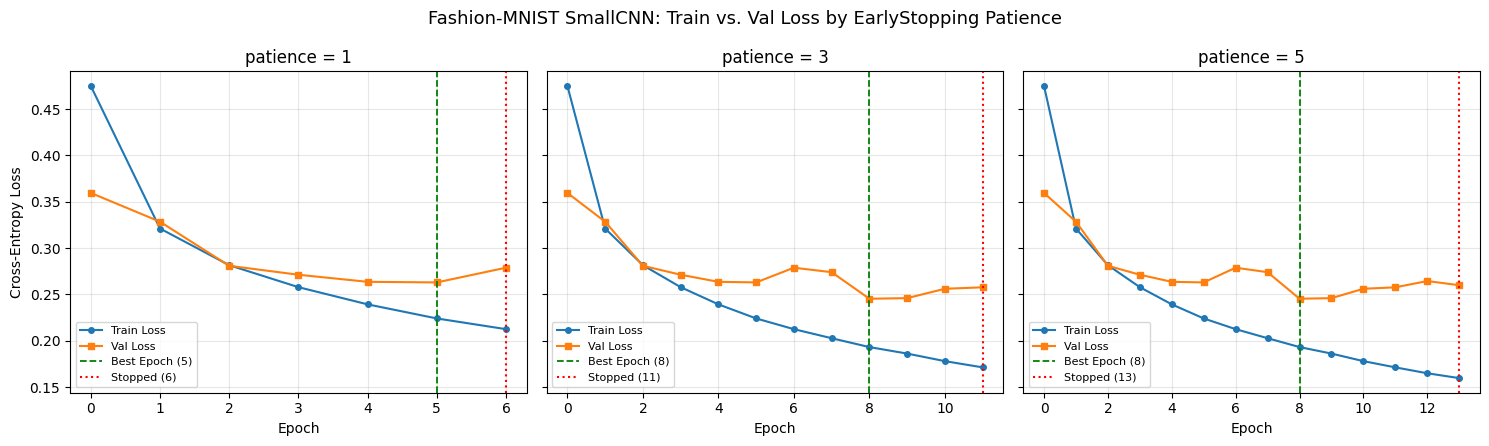

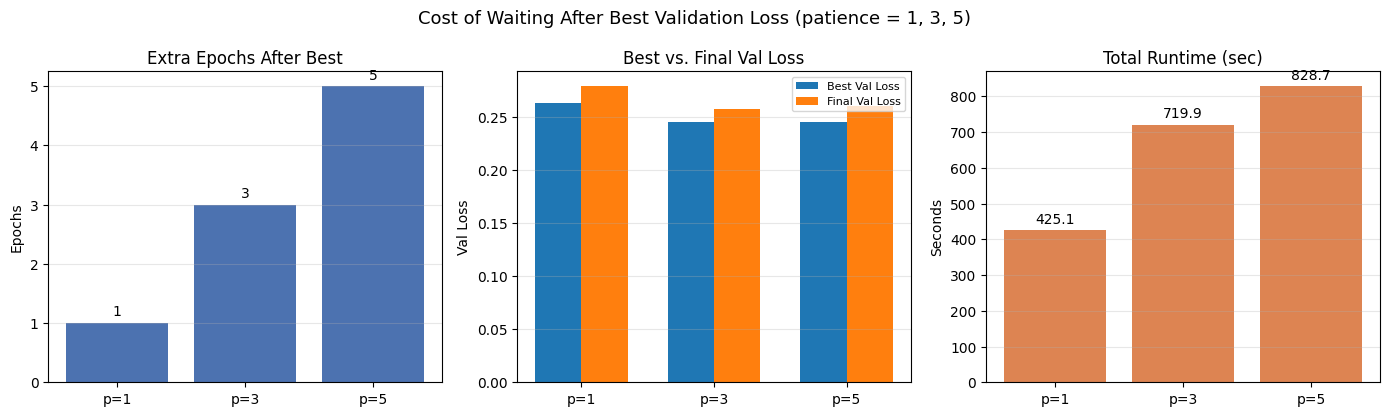

In [5]:
import matplotlib.pyplot as plt

# Figure 1: Training vs. Validation Loss Curves across Patience Values
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
fig.suptitle(
    "Fashion-MNIST SmallCNN: Train vs. Val Loss by EarlyStopping Patience",
    fontsize=13,
)

for ax, p in zip(axes, patience_values):
  sub = curves_df[curves_df["patience"] == p]
  s_row = summary_df[summary_df["patience"] == p].iloc[0]

  ax.plot(
      sub["epoch"],
      sub["train_loss"],
      marker="o",
      markersize=4,
      label="Train Loss",
  )
  ax.plot(
      sub["epoch"], sub["val_loss"], marker="s", markersize=4, label="Val Loss"
  )
  ax.axvline(
      s_row["best_epoch"],
      color="green",
      linestyle="--",
      linewidth=1.3,
      label=f"Best Epoch ({int(s_row['best_epoch'])})",
  )
  ax.axvline(
      s_row["stopped_epoch"],
      color="red",
      linestyle=":",
      linewidth=1.5,
      label=f"Stopped ({int(s_row['stopped_epoch'])})",
  )

  ax.set_title(f"patience = {p}")
  ax.set_xlabel("Epoch")
  ax.grid(True, alpha=0.3)
  ax.legend(fontsize=8)

axes[0].set_ylabel("Cross-Entropy Loss")
plt.tight_layout()
plt.savefig("fig1_loss_curves_patience.png", dpi=200, bbox_inches="tight")
plt.show()

# Figure 2: Cost of Extra Epochs After Best Val Loss (Overfit Drift & Runtime)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
fig.suptitle(
    "Cost of Waiting After Best Validation Loss (patience = 1, 3, 5)",
    fontsize=13,
)

x_labels = [f"p={p}" for p in summary_df["patience"]]

# Panel A: Extra epochs after best val_loss
bars0 = axes[0].bar(
    x_labels, summary_df["extra_epochs_after_best"], color="#4C72B0"
)
axes[0].set_title("Extra Epochs After Best")
axes[0].set_ylabel("Epochs")
axes[0].bar_label(bars0, padding=3)

# Panel B: Best Val Loss vs. Final Val Loss
width = 0.35
x_idx = range(len(summary_df))
bars1 = axes[1].bar(
    [i - width / 2 for i in x_idx],
    summary_df["best_val_loss"],
    width,
    label="Best Val Loss",
)
bars2 = axes[1].bar(
    [i + width / 2 for i in x_idx],
    summary_df["final_val_loss"],
    width,
    label="Final Val Loss",
)
axes[1].set_title("Best vs. Final Val Loss")
axes[1].set_ylabel("Val Loss")
axes[1].set_xticks(list(x_idx))
axes[1].set_xticklabels(x_labels)
axes[1].legend(fontsize=8)

# Panel C: Elapsed Runtime (seconds)
bars3 = axes[2].bar(x_labels, summary_df["elapsed_sec"], color="#DD8452")
axes[2].set_title("Total Runtime (sec)")
axes[2].set_ylabel("Seconds")
axes[2].bar_label(bars3, fmt="%.1f", padding=3)

for ax in axes:
  ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("fig2_patience_cost_summary.png", dpi=200, bbox_inches="tight")
plt.show()

### Visualizing Stopping Curves and Extra-Epoch Costs
Generates two summary figures from `curves_df` and `summary_df`:
- **Figure 1 (`fig1_loss_curves_patience.png`):** Per-epoch training vs. validation loss across `patience = 1, 3, 5`, marking the best checkpoint epoch and actual stopping epoch.
- **Figure 2 (`fig2_patience_cost_summary.png`):** Compares extra epochs run after the best validation loss (`1`, `3`, `5`), post-best validation loss drift (`Best` vs. `Final`), and total wall-clock runtime (`425.1s`, `719.9s`, `828.7s`).